# Когортный анализ удержания пользователей

**Вопрос:** какая доля новых пользователей возвращается в продукт через 1, 2 и 3 месяца после регистрации?

Данные синтетические. Когорта определяется месяцем регистрации.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

users = pd.read_csv("data/users.csv", parse_dates=["signup_date"])
activity = pd.read_csv("data/activity.csv", parse_dates=["activity_date"])
users.head()

,user_id,signup_date,signup_source
0,USR00001,2026-01-22,organic
1,USR00002,2026-02-07,referral
2,USR00003,2026-01-16,paid_ads
3,USR00004,2026-01-20,referral
4,USR00005,2026-03-02,organic


## 1. Подготовим данные

Добавим месяц регистрации (когорту) к пользователям, а затем присоединим его к событиям.

In [2]:
users["cohort_month"] = users["signup_date"].dt.to_period("M")
activity = activity.merge(users[["user_id", "cohort_month"]], on="user_id", how="left")
activity["activity_month"] = activity["activity_date"].dt.to_period("M")

activity["months_since_signup"] = (
    (activity["activity_month"].dt.year - activity["cohort_month"].dt.year) * 12
    + activity["activity_month"].dt.month
    - activity["cohort_month"].dt.month
)
activity.head()

,user_id,activity_date,event_name,cohort_month,activity_month,months_since_signup
0,USR00001,2026-01-31,session,2026-01,2026-01,0
1,USR00001,2026-02-10,content_view,2026-01,2026-02,1
2,USR00001,2026-02-10,session,2026-01,2026-02,1
3,USR00001,2026-02-10,content_view,2026-01,2026-02,1
4,USR00002,2026-02-24,content_view,2026-02,2026-02,0


## 2. Посчитаем размеры когорт и активных пользователей

Считаем уникальных пользователей, а не строки событий: один человек мог совершить несколько действий за месяц.

In [3]:
cohort_sizes = users.groupby("cohort_month")["user_id"].nunique()
active_users = (
    activity.groupby(["cohort_month", "months_since_signup"])["user_id"]
            .nunique()
            .unstack(fill_value=0)
)

retention = active_users.div(cohort_sizes, axis=0)
retention = retention.reindex(columns=[0, 1, 2, 3])
retention.columns = ["Month 0", "Month 1", "Month 2", "Month 3"]
retention.round(3)

,Month 0,Month 1,Month 2,Month 3
cohort_month,,,,
2026-01,1.0,0.494,0.389,0.293
2026-02,1.0,0.487,0.345,0.256
2026-03,1.0,0.476,0.368,0.286
2026-04,1.0,0.452,0.384,0.316


## 3. Построим тепловую карту

В каждой ячейке — доля пользователей когорты, у которых была хотя бы одна активность в соответствующем месяце после регистрации.

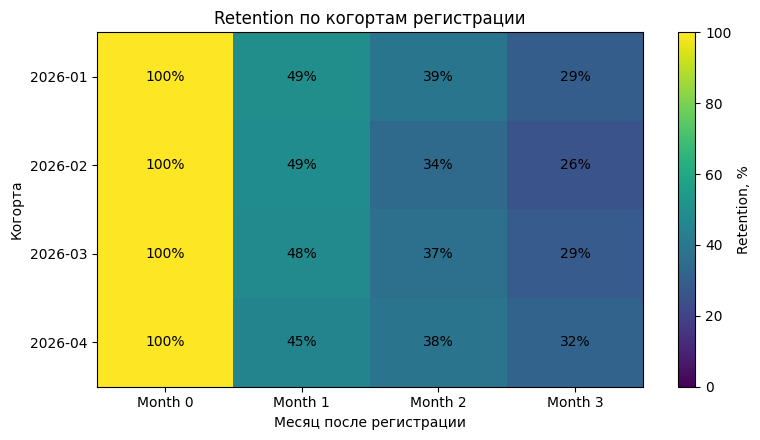

In [4]:
fig, ax = plt.subplots(figsize=(8, 4.5))
im = ax.imshow(retention.values * 100, aspect="auto", vmin=0, vmax=100)
ax.set_xticks(range(len(retention.columns)), labels=retention.columns)
ax.set_yticks(range(len(retention.index)), labels=[str(x) for x in retention.index])
ax.set_title("Retention по когортам регистрации")
ax.set_xlabel("Месяц после регистрации")
ax.set_ylabel("Когорта")
for i in range(retention.shape[0]):
    for j in range(retention.shape[1]):
        value = retention.iloc[i, j]
        if pd.notna(value):
            ax.text(j, i, f"{value:.0%}", ha="center", va="center")
fig.colorbar(im, ax=ax, label="Retention, %")
plt.tight_layout()
Path("results").mkdir(exist_ok=True)
plt.savefig("results/retention_heatmap.png", dpi=150)
plt.show()

## 4. Короткий итог

Посмотрим на среднее удержание по доступным когортам. При сравнении важно помнить, что когорты могут отличаться по источнику, сезону и составу пользователей.

In [5]:
retention.mean().mul(100).round(1).rename("Average retention, %")

Month 0    100.0
Month 1     47.7
Month 2     37.1
Month 3     28.8
Name: Average retention, %, dtype: float64

## Ограничения анализа

- Данные искусственные и отражают упрощённый сценарий.
- В реальном продукте нужно заранее договориться, что считать активностью.
- Retention показывает факт возвращения, но не объясняет причины поведения.
- При сравнении когорт важно учитывать доступный период наблюдения.